# Run na banku: když se události nakazí navzájem

*Nad rámec skripta — aplikace.*

---

Pojišťovna v `pojistovna_realisticky` měla škody, které přicházely **nezávisle**. I shluky (jedna nehoda, víc účastníků) byly jen větší balíčky — jeden balíček o dalším nic nevěděl.

Run na banku je jiný. Lidé vybírají, protože **vidí, že vybírají ostatní**. Každý výběr zvyšuje pravděpodobnost dalšího. Tomu se říká **samobuzený proces** (Hawkes, 1971) a je to poslední chybějící mechanismus v repozitáři: **zpětná vazba v čase**.

Model zapíšeme v podobě, která dává přesnou kontrolu. Každý výběr má dvě příčiny:

- **sám od sebe** (imigrant): lidé přicházejí svou cestou, intenzita $\mu$,
- **nákaza**: každý výběr vyvolá $\operatorname{Poisson}(n)$ dalších výběrů s náhodným zpožděním.

Číslo $n$ je **větvící poměr** a je to přesně $R_0$ ze sešitu `vetvici_proces` — každý výběr „nakazí" v průměru $n$ dalších. Odtud plyne všechno:

$$\text{střední velikost shluku} = \frac{1}{1-n}, \qquad \text{celková intenzita} = \frac{\mu}{1-n},$$

a pro $n \ge 1$ je proces **nestabilní** — run se nezastaví sám.

In [1]:
import math
import random

import matplotlib.pyplot as plt

random.seed(1)  # opakovatelné výsledky


def poisson(lam):
    if lam > 60:
        return max(0, int(round(random.gauss(lam, math.sqrt(lam)))))
    L, p, k = math.exp(-lam), 1.0, 0
    while True:
        p *= random.random()
        if p < L:
            return k
        k += 1


def estimate(xs):
    n = len(xs)
    m = sum(xs) / n
    var = sum((x - m) ** 2 for x in xs) / (n - 1)
    return m, math.sqrt(var / n)

## 1. Velikost lavina: přesná kontrola

Nejdřív ověříme tu teorii. Jeden výběr spustí lavinu: on sám, jeho „potomci", jejich potomci… To je **přesně větvící proces** z `vetvici_proces`, jen se potomci neobjevují v generacích, ale rozprostření v čase.

Střední velikost laviny plyne z prostého součtu generací:

$$1 + n + n^2 + n^3 + \dots = \frac{1}{1-n} \qquad (n < 1).$$

In [2]:
def velikost_laviny(n, strop=100_000):
    """Kolik výběrů celkem vyvolá jeden spontánní výběr (včetně sebe)."""
    celkem, generace = 0, 1
    while generace > 0 and celkem < strop:
        celkem += generace
        generace = (poisson(generace * n) if generace >= 2000
                    else sum(poisson(n) for _ in range(generace)))
    return celkem


print(f"{'n':>5s} {'střední velikost laviny':>26s} {'přesně 1/(1-n)':>16s}")
for n in (0.0, 0.3, 0.5, 0.8, 0.9):
    vz = [velikost_laviny(n) for _ in range(20_000)]
    m, se = estimate(vz)
    print(f"{n:>5.1f} {m:>18.3f} +- {se:.3f} {1 / (1 - n):>16.3f}")
    assert abs(m - 1 / (1 - n)) < 5 * se + 1e-9   # +eps: pro n = 0 je rozptyl nulový

print("\nPři n = 0.9 vyvolá jeden výběr v průměru deset dalších. A jak uvidíme,")
print("ten průměr je ošidný: většina lavin je malá, pár jich je obrovských.")

    n    střední velikost laviny   přesně 1/(1-n)
  0.0              1.000 +- 0.000            1.000
  0.3              1.437 +- 0.007            1.429
  0.5              1.996 +- 0.014            2.000
  0.8              5.072 +- 0.072            5.000
  0.9             10.261 +- 0.215           10.000

Při n = 0.9 vyvolá jeden výběr v průměru deset dalších. A jak uvidíme,
ten průměr je ošidný: většina lavin je malá, pár jich je obrovských.


## 2. Fázový přechod a proč je nebezpečný

Jako u větvícího procesu je zlom v $n = 1$. Pod ním se lavina vždycky zastaví, nad ním nemusí. Jenže je tu věc, která dělá runy tak zrádné:

**Těsně pod jedničkou vypadá systém klidně, ale laviny už mají obrovský rozptyl.**

Střední velikost $1/(1-n)$ roste do nekonečna, ale **rozptyl roste mnohem rychleji**. Banka při $n = 0.9$ vidí většinu dní naprosto normální provoz — a jednou za čas lavinu stokrát větší než průměr.

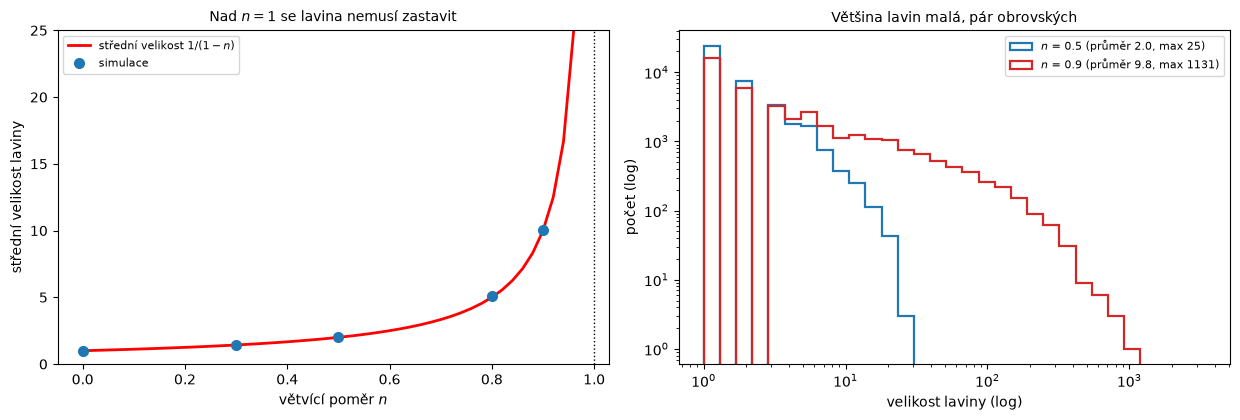

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.3))

ax = axes[0]
nn = [0.02 * i for i in range(50)]
ax.plot(nn, [1 / (1 - n) for n in nn], "r-", lw=2, label="střední velikost $1/(1-n)$")
nn_sim = (0.0, 0.3, 0.5, 0.8, 0.9)
ax.plot(nn_sim, [estimate([velikost_laviny(n) for _ in range(6000)])[0] for n in nn_sim],
        "o", ms=7, label="simulace")
ax.axvline(1.0, color="k", ls=":", lw=1)
ax.set_xlabel("větvící poměr $n$")
ax.set_ylabel("střední velikost laviny")
ax.set_ylim(0, 25)
ax.set_title("Nad $n = 1$ se lavina nemusí zastavit", fontsize=10)
ax.legend(fontsize=8)

ax = axes[1]
for n, barva in ((0.5, "tab:blue"), (0.9, "tab:red")):
    vz = [velikost_laviny(n) for _ in range(40_000)]
    ax.hist(vz, bins=[1.3**i for i in range(0, 32)], histtype="step", lw=1.6,
            color=barva, label=f"$n$ = {n} (průměr {sum(vz) / len(vz):.1f}, max {max(vz)})")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("velikost laviny (log)")
ax.set_ylabel("počet (log)")
ax.set_title("Většina lavin malá, pár obrovských", fontsize=10)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

Pravý graf je ten podstatný. Při $n = 0.9$ je **medián laviny pořád jedna** — drtivá většina výběrů nikoho nenakazí. Ale chvost sahá do stovek. Z běžného provozu se proto nepozná, jak blízko k jedničce systém je; vypadá klidně až do chvíle, kdy nevypadá.

## 3. Jak to vypadá v čase

Teď proces se skutečným časem: imigranti přicházejí s intenzitou $\mu$, každý výběr vyvolá potomky s exponenciálním zpožděním.

    n   výběrů celkem   přesně μT/(1-n)   z toho spontánních
  0.0      97.7 +-  1.6             100.0                 97.7
  0.5     204.7 +-  6.0             200.0                101.7
  0.8     491.4 +- 15.6             500.0                 98.2
  0.9    1032.8 +- 47.8            1000.0                101.8

(Simulace kolísá kolem vzorce v rámci směrodatné chyby. V šumu se skrývá drobný posun dolů:
 potomci, kteří by přišli až po čase T, se nezapočítají, a čím větší n, tím víc se jich utne.)


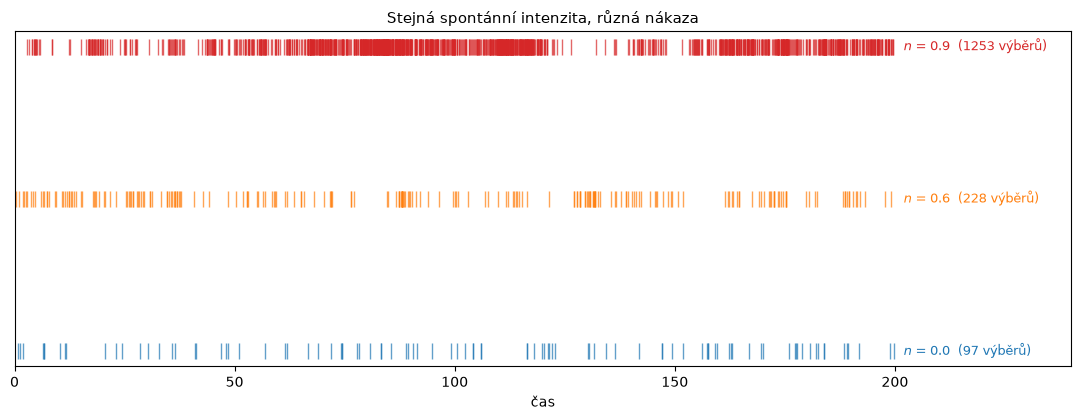

Shora dolů přibývá shlukování. Spontánních výběrů je ve všech řádcích stejně —
liší se jen to, kolik jich každý vyvolá dál. Při n = 0.9 se výběry slévají
do shluků, které z dálky vypadají jako panika, ačkoliv se model nezměnil.


In [4]:
def simuluj_v_case(mu, n, T, stredni_zpozdeni=1.0, strop=200_000):
    """Hawkesův proces přes imigraci a větvení. Vrací časy všech výběrů."""
    casy = []
    # spontánní příchody: Poissonův proces s intenzitou mu
    t = 0.0
    zarodky = []
    while True:
        t += random.expovariate(mu)
        if t > T:
            break
        zarodky.append(t)
    fronta = list(zarodky)
    while fronta and len(casy) < strop:
        t0 = fronta.pop()
        casy.append(t0)
        for _ in range(poisson(n)):
            t1 = t0 + random.expovariate(1 / stredni_zpozdeni)
            if t1 <= T:
                fronta.append(t1)
    return sorted(casy), len(zarodky)


MU, T = 0.5, 200.0
print(f"{'n':>5s} {'výběrů celkem':>15s} {'přesně μT/(1-n)':>17s} {'z toho spontánních':>20s}")
for n in (0.0, 0.5, 0.8, 0.9):
    celkem, spont = [], []
    for _ in range(30):
        c, z = simuluj_v_case(MU, n, T)
        celkem.append(len(c)); spont.append(z)
    m, se = estimate(celkem)
    print(f"{n:>5.1f} {m:>9.1f} +- {se:>4.1f} {MU * T / (1 - n):>17.1f} {sum(spont) / len(spont):>20.1f}")

print("\n(Simulace kolísá kolem vzorce v rámci směrodatné chyby. V šumu se skrývá drobný posun dolů:")
print(" potomci, kteří by přišli až po čase T, se nezapočítají, a čím větší n, tím víc se jich utne.)")

fig, ax = plt.subplots(figsize=(11, 4.3))
for i, (n, barva) in enumerate(((0.0, "tab:blue"), (0.6, "tab:orange"), (0.9, "tab:red"))):
    casy, _ = simuluj_v_case(MU, n, T)
    ax.plot(casy, [i] * len(casy), "|", ms=12, color=barva, alpha=0.7)
    ax.text(T * 1.01, i, f"$n$ = {n}  ({len(casy)} výběrů)", va="center", fontsize=9, color=barva)
ax.set_yticks([])
ax.set_xlim(0, T * 1.2)
ax.set_xlabel("čas")
ax.set_title("Stejná spontánní intenzita, různá nákaza", fontsize=11)
plt.tight_layout()
plt.show()

print("Shora dolů přibývá shlukování. Spontánních výběrů je ve všech řádcích stejně —")
print("liší se jen to, kolik jich každý vyvolá dál. Při n = 0.9 se výběry slévají")
print("do shluků, které z dálky vypadají jako panika, ačkoliv se model nezměnil.")

## 4. Co z toho plyne

Tři věci, které tenhle model říká a které nejsou samozřejmé:

**Shluky nepotřebují příčinu.** Poslední obrázek vypadá, jako by v některých chvílích „přišla zpráva" a lidé začali panikařit. Nepřišla. Model je po celou dobu stejný a intenzita imigrantů konstantní — shluky vyrobila jen zpětná vazba. **Hledat pro každý shluk vnější příčinu je omyl.**

**Běžný provoz neprozradí, jak blízko k hraně jste.** Medián laviny je 1 i při $n = 0.9$. Rozdíl mezi bezpečným a nebezpečným systémem je vidět až na chvostu, tedy v datech, která skoro nikdy nemáte.

**Zásah musí mířit na $n$, ne na $\mu$.** Snížit spontánní výběry (třeba uklidňující zprávou) sníží celkový počet úměrně. Ale snížit nákazu $n$ z 0.9 na 0.8 zmenší laviny dvojnásobně — a z 0.95 na 0.9 taky. Blízko jedničky má každý kousek obrovskou páku, přesně jako u $R_0$ v epidemii.

In [5]:
print("Co pomůže víc: snížit spontánní výběry, nebo nákazu?\n")
MU0, N0 = 0.5, 0.9
zaklad = MU0 * T / (1 - N0)
print(f"výchozí stav: μ = {MU0}, n = {N0}  ->  očekávaných výběrů {zaklad:.0f}")
print(f"\n{'zásah':>34s} {'výběrů':>10s} {'změna':>9s}")
for popis, mu_, n_ in (("snížit μ o 20 % (uklidnit veřejnost)", MU0 * 0.8, N0),
                       ("snížit n o 20 % (zpomalit nákazu)", MU0, N0 * 0.8),
                       ("obojí o 10 %", MU0 * 0.9, N0 * 0.9)):
    oc = mu_ * T / (1 - n_)
    print(f"{popis:>34s} {oc:>10.0f} {oc / zaklad - 1:>8.0%}")

print("\nSnížit nákazu je u systému blízko hranice nesrovnatelně účinnější —")
print("μ vstupuje do vzorce lineárně, zatímco n přes 1/(1-n).")

Co pomůže víc: snížit spontánní výběry, nebo nákazu?

výchozí stav: μ = 0.5, n = 0.9  ->  očekávaných výběrů 1000

                             zásah     výběrů     změna
snížit μ o 20 % (uklidnit veřejnost)        800     -20%
 snížit n o 20 % (zpomalit nákazu)        357     -64%
                      obojí o 10 %        474     -53%

Snížit nákazu je u systému blízko hranice nesrovnatelně účinnější —
μ vstupuje do vzorce lineárně, zatímco n přes 1/(1-n).


## Shrnutí

| Pojem | Co si pamatovat |
|-------|-----------------|
| Samobuzený proces | každá událost zvyšuje intenzitu dalších (Hawkes) |
| Větvící poměr $n$ | průměrný počet událostí vyvolaných jednou událostí — totéž co $R_0$ |
| Velikost laviny | $1/(1-n)$ přesně; je to součet generací $1 + n + n^2 + \dots$ |
| Celková intenzita | $\mu/(1-n)$ — spontánní výběry zesílené nákazou |
| Stabilita | $n < 1$ se zastaví, $n \ge 1$ nemusí |
| Zrádnost | medián laviny je 1 i při $n = 0.9$; nebezpečí je vidět jen na chvostu |
| Shluky bez příčiny | zpětná vazba vyrobí shluky bez jakékoli vnější události |
| Kam zasáhnout | na $n$, ne na $\mu$ — $n$ působí přes $1/(1-n)$ |

Tím se repozitář uzavírá: `vetvici_proces` měl zpětnou vazbu v generacích, tenhle sešit ji má v čase, a `perkolace` tentýž fázový přechod v prostoru. Všechny tři mají zlom v jednom bodě a ve všech třech platí, že těsně pod ním systém vypadá v pořádku.

### Zkuste si

1. Ověřte vzorec pro **rozptyl** velikosti laviny, $\dfrac{n}{(1-n)^3}$ (pro Poissonovy potomky). Potvrdí se, že roste mnohem rychleji než střední hodnota?
2. Nahraďte exponenciální zpoždění **mocninným** (dlouhá paměť, jako u aftershocků zemětřesení). Změní se velikost lavin, nebo jen jejich rozložení v čase?
3. Přidejte bance **rezervu**: zkrachuje, když počet výběrů za den překročí práh. Spočítejte pravděpodobnost krachu v závislosti na $n$.
4. Odhadněte $n$ z pozorovaných dat (jen z časů výběrů, bez znalosti, kdo koho nakazil). Jak přesně to jde?
5. Zaveďte zásah: při překročení prahu se $n$ sníží na polovinu (banka omezí výběry). O kolik to pomůže a jak brzy musí zásah přijít?
6. Porovnejte rozdělení velikosti laviny při $n = 0.99$ s mocninným rozdělením. Blíží se mu? (U kritického větvícího procesu má exponent $-3/2$.)